<a href="https://colab.research.google.com/github/Ansarss/Ai_learning_experiments/blob/main/LSTM_Residency_Executable_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Reproducible synthetic demonstration: construction RFI response-delay risk

All examples are synthetic, independently generated project windows. They do not represent actual customer data, empirical operational effectiveness, an implemented production service, or contractual deadline calculations.

**Research question:** Do 30-day project histories contain predictive information that an LSTM uses better than a 7-day LSTM, a temporal CNN, or an interpretable logistic baseline? What happens when the recording process and the target relationship shift?



### Training log, entry 1: data assumptions
Each independent simulated project contributes 30 complete daily vectors. Predictors are new RFIs, recorded resolutions, open backlog, reviewer availability, revision indicator, and a simulated backlog-derived *age-pressure proxy*. The binary label is randomly generated from a declared risk function of history, with stochastic noise; it is not a label from actual RFI due dates. The shift scenario changes the risk-generating relationship and makes recorded closures include extra acknowledgments.

Because each project window is independent, train/validation/test cohorts are non-overlapping. This is not a genuine chronological field study; a deployed evaluation should use temporal and project-group holdouts.

In [ ]:
"""Reproducible illustrative synthetic experiment for residency artifact (no real company data)."""
import json, os, random
from pathlib import Path
import numpy as np
import torch
from torch import nn
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score,
                             precision_score, recall_score, f1_score, brier_score_loss,
                             confusion_matrix)
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

SEED=731
np.random.seed(SEED); random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(2)
OUT=Path('lstm_residency_outputs'); OUT.mkdir(exist_ok=True)

FEATURE_NAMES=['New RFIs','Resolved RFIs (recorded)','Open RFI backlog','Reviewer availability','Drawing revision','Age pressure index']

def make_data(n, seed, drift=False):
    rng=np.random.default_rng(seed)
    X=np.zeros((n,30,6),dtype=np.float32)
    ys=np.zeros(n,dtype=np.int64)
    truths=np.zeros(n,dtype=np.float32)
    for j in range(n):
        arrival_base=rng.uniform(3.3,8.2)
        reviewer_base=rng.uniform(3.6,9.0)
        backlog=rng.uniform(2,16)
        shortage_start=int(rng.integers(4,24))
        shortage_duration=int(rng.integers(4,10))
        shortage_flag=rng.random()<0.54
        revision_early=(rng.random()<0.68)
        revision_start=int(rng.integers(2,9))
        revision_late=(rng.random()<0.35)
        late_start=int(rng.integers(20,26))
        for t in range(30):
            staff=max(0.37,min(1.16,1.0+rng.normal(0,.105)))
            if shortage_flag and shortage_start<=t<shortage_start+shortage_duration:
                staff*=rng.uniform(.50,.77)
            revision=int((revision_early and t in [revision_start,revision_start+1]) or
                         (revision_late and t==late_start) or (rng.random()<.025))
            arrivals=rng.poisson(arrival_base*(1+.44*revision))
            resolved=rng.poisson(reviewer_base*staff*(1-.12*revision))
            backlog=max(0,min(80,backlog+arrivals-resolved))
            age_pressure=1/(1+np.exp(-((backlog-15)/8))) + rng.normal(0,.045)
            X[j,t]=[arrivals,resolved,backlog,staff,revision,np.clip(age_pressure,0,1)]
        b=X[j,:,2]; staff=X[j,:,3]; rev=X[j,:,4]
        early_rev=rev[2:11].sum(); late_rev=rev[20:30].sum()
        last=b[-7:].mean(); prior=b[8:15].mean(); chronic=b.mean(); trend=last-prior
        last_norm=np.tanh((last-20)/14); chronic_norm=np.tanh((chronic-20)/14)
        trend_norm=np.tanh(trend/12)
        if not drift:
            z=(-.60 + .75*last_norm + .36*chronic_norm + .95*(early_rev>=2)
               + .30*(early_rev>=1)*(last>18) + .48*trend_norm
               - 1.15*(staff[-7:].mean()-1) + .28*(late_rev>=1) + rng.normal(0,.54))
        else:
            # Hypothetical new routing policy: heavily backlogged queues are
            # proactively escalated, while some low-backlog external tasks are
            # missed. Earlier drawing revisions no longer identify risk.
            # Recorded resolutions also count acknowledgments (measurement shift).
            z=(-.30 - .55*last_norm - .22*chronic_norm - .45*(early_rev>=2)
               + .25*trend_norm - .45*(staff[-7:].mean()-1)
               + 1.00*(late_rev>=1) + rng.normal(0,.54))
            X[j,:,1]+=rng.poisson(2.5,size=30).astype(np.float32)  # recording change ONLY
        p=1/(1+np.exp(-np.clip(z,-15,15)))
        truths[j]=p
        ys[j]=int(rng.random()<p)
    return X,ys,truths



In [ ]:
X_train,y_train,_=make_data(1400,101)
X_val,y_val,_=make_data(320,102)
X_test,y_test,_=make_data(400,103)
X_shift,y_shift,_=make_data(400,104,drift=True)
scaler=StandardScaler().fit(X_train.reshape(-1,6))
Xtr=scaler.transform(X_train.reshape(-1,6)).reshape(-1,30,6).astype(np.float32)
Xva=scaler.transform(X_val.reshape(-1,6)).reshape(-1,30,6).astype(np.float32)
Xte=scaler.transform(X_test.reshape(-1,6)).reshape(-1,30,6).astype(np.float32)
Xsh=scaler.transform(X_shift.reshape(-1,6)).reshape(-1,30,6).astype(np.float32)



### Training log, entry 2: architectural choices
The LSTM uses 32 hidden units and a small dense head. The 1D CNN uses two convolutional layers (kernel 5; the second dilated) and a dense head. The baseline is logistic regression on the flattened 30-day history. A **7-day LSTM ablation** tests whether older sequence elements help. Models use the same held-out project cohort and 0.50 classification threshold. The experiment compares these implementations, not every possible CNN/RNN variant.

For LSTM, the cell state `cₜ` and hidden state `hₜ` are learned numerical tensors. Forget, input, and output gates regulate numerical information flow; they should not be interpreted as explicit records of project events.

In [ ]:
class LSTMModel(nn.Module):
    def __init__(self):
        super().__init__(); self.lstm=nn.LSTM(input_size=6,hidden_size=32,batch_first=True)
        self.head=nn.Sequential(nn.Linear(32,16),nn.ReLU(),nn.Linear(16,1))
    def forward(self,x):
        _,(h,c)=self.lstm(x); return self.head(h[-1]).squeeze(-1)

class CNNModel(nn.Module):
    def __init__(self):
        super().__init__(); self.conv=nn.Sequential(nn.Conv1d(6,24,5,padding=2),nn.ReLU(),
                     nn.Conv1d(24,16,5,padding=4,dilation=2),nn.ReLU())
        self.head=nn.Sequential(nn.Flatten(),nn.Linear(16*30,32),nn.ReLU(),nn.Linear(32,1))
    def forward(self,x): return self.head(self.conv(x.transpose(1,2))).squeeze(-1)

def train(model,name,epochs=22,window=30):
    torch.manual_seed(SEED+ (7 if name=='LSTM' else 13))
    model.train(); optimizer=torch.optim.Adam(model.parameters(),lr=.002,weight_decay=1e-4)
    loss_fn=nn.BCEWithLogitsLoss(); X_t=torch.tensor(Xtr[:,-window:,:]); y_t=torch.tensor(y_train.astype(np.float32))
    X_v=torch.tensor(Xva[:,-window:,:]); y_v=torch.tensor(y_val.astype(np.float32))
    hist={'train':[],'val':[]}; best=float('inf'); best_state=None; waited=0
    for epoch in range(epochs):
        order=torch.randperm(len(X_t)); losses=[]; model.train()
        for ix in order.split(96):
            optimizer.zero_grad(); logits=model(X_t[ix]); loss=loss_fn(logits,y_t[ix]);
            loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(),1.0)
            optimizer.step(); losses.append((loss.item(),len(ix)))
        train_loss=sum(a*b for a,b in losses)/len(X_t)
        model.eval()
        with torch.no_grad(): vloss=loss_fn(model(X_v),y_v).item()
        hist['train'].append(float(train_loss));hist['val'].append(float(vloss))
        if vloss < best-0.0008:
            best=vloss;waited=0;best_state={k:v.detach().clone() for k,v in model.state_dict().items()}
        else:
            waited+=1
            if waited>=5: break
    model.load_state_dict(best_state); model.eval()
    return hist



In [ ]:
lstm=LSTMModel(); cnn=CNNModel()
LSTM_HISTORY=train(lstm,'LSTM');CNN_HISTORY=train(cnn,'CNN')
lstm_short=LSTMModel(); SHORT_HISTORY=train(lstm_short,'LSTM7',window=7)
logreg=LogisticRegression(max_iter=1300,C=0.3,random_state=SEED)
logreg.fit(Xtr.reshape(len(Xtr),-1),y_train)

def probs(model,X):
    if model=='Logistic Regression': return logreg.predict_proba(X.reshape(len(X),-1))[:,1]
    nnmodel=lstm if model=='LSTM' else lstm_short if model=='LSTM (7-day)' else cnn
    with torch.no_grad():return torch.sigmoid(nnmodel(torch.from_numpy(X[:,-7:,:] if model=='LSTM (7-day)' else X))).numpy()



### Training log, entry 3: test before interpreting
Models are selected using validation loss with early stopping. The held-out test is not used for parameter fitting or stopping. We report PR-AUC, ROC-AUC, F1, precision, recall, accuracy, Brier score, and confusion counts. PR-AUC depends on outcome prevalence, so compare it against each cohort's prevalence and do not assume it is portable across projects.

In [ ]:
models=['LSTM','LSTM (7-day)','1D CNN','Logistic Regression']
def score(y,p):
    lab=(p>=0.5).astype(int)
    return {'ROC-AUC':float(roc_auc_score(y,p)), 'PR-AUC':float(average_precision_score(y,p)),
            'F1':float(f1_score(y,lab,zero_division=0)), 'Precision':float(precision_score(y,lab,zero_division=0)),
            'Recall':float(recall_score(y,lab,zero_division=0)), 'Brier':float(brier_score_loss(y,p)),
            'Accuracy':float(accuracy_score(y,lab)), 'TP':int(confusion_matrix(y,lab)[1,1]),
            'FN':int(confusion_matrix(y,lab)[1,0]), 'FP':int(confusion_matrix(y,lab)[0,1]),
            'TN':int(confusion_matrix(y,lab)[0,0])}
results={name:{'held_out':score(y_test,probs(name,Xte)), 'shift':score(y_shift,probs(name,Xsh))} for name in models}
print('positive rates',*[f'{v:.3f}' for v in [y_train.mean(),y_val.mean(),y_test.mean(),y_shift.mean()]])
for n in models:
 print(n,'test', {k:round(v,3) for k,v in results[n]['held_out'].items() if k in ['ROC-AUC','PR-AUC','F1','Brier']},'shift',{k:round(v,3) for k,v in results[n]['shift'].items() if k in ['ROC-AUC','PR-AUC','F1','Brier']})



positive rates 0.565 0.572 0.583 0.482
LSTM test {'ROC-AUC': 0.749, 'PR-AUC': 0.77, 'F1': 0.745, 'Brier': 0.193} shift {'ROC-AUC': 0.443, 'PR-AUC': 0.445, 'F1': 0.376, 'Brier': 0.335}
LSTM (7-day) test {'ROC-AUC': 0.747, 'PR-AUC': 0.769, 'F1': 0.751, 'Brier': 0.193} shift {'ROC-AUC': 0.44, 'PR-AUC': 0.437, 'F1': 0.378, 'Brier': 0.339}
1D CNN test {'ROC-AUC': 0.769, 'PR-AUC': 0.821, 'F1': 0.736, 'Brier': 0.193} shift {'ROC-AUC': 0.44, 'PR-AUC': 0.448, 'F1': 0.401, 'Brier': 0.326}
Logistic Regression test {'ROC-AUC': 0.743, 'PR-AUC': 0.794, 'F1': 0.724, 'Brier': 0.207} shift {'ROC-AUC': 0.436, 'PR-AUC': 0.438, 'F1': 0.463, 'Brier': 0.364}


### Training log, entry 4: What did it remember?
We perform three **diagnostics**, not causal interventions: (1) set early revision flags to zero without recalculating correlated project features; (2) increase the recorded last-week availability feature; and (3) reorder days 1–20 as whole vectors. These tests perturb the original data-generating logic, so any prediction difference describes sensitivity, **not** a reliable business explanation. The 7-vs-30-day ablation offers an additional empirical check of whether long histories help.

In [ ]:
# Memory sensitivity diagnostic: hide the early (days 3..11) revision indicators;
# keep other channels unchanged, so this is not a physically valid intervention.
base=probs('LSTM',Xte)
masked=X_test.copy(); masked[:,2:11,4]=0
masked_scaled=scaler.transform(masked.reshape(-1,6)).reshape(-1,30,6).astype(np.float32)
pr_masked=probs('LSTM',masked_scaled)
affected=(X_test[:,2:11,4].sum(axis=1)>0)
mean_early_abs_delta=float(np.abs(base[affected]-pr_masked[affected]).mean())
mean_early_signed_delta=float((base[affected]-pr_masked[affected]).mean())

# More recent feature perturbation, all projects.
modified=X_test.copy(); modified[:,-7:,3]=np.minimum(1.16,modified[:,-7:,3]+.2)
modified_scaled=scaler.transform(modified.reshape(-1,6)).reshape(-1,30,6).astype(np.float32)
pr_staff=probs('LSTM',modified_scaled)
mean_staff_abs_delta=float(np.abs(base-pr_staff).mean())

# Test if historical order matters, shuffling early 20 days (entire vectors):
rng=np.random.default_rng(901)
shuffled=X_test.copy()
for idx in range(len(shuffled)):
    perm=rng.permutation(20)
    shuffled[idx,:20,:]=X_test[idx,perm,:]
shuffled_scaled=scaler.transform(shuffled.reshape(-1,6)).reshape(-1,30,6).astype(np.float32)
pr_shuffle=probs('LSTM',shuffled_scaled)
shuffle_abs_delta=float(np.abs(base-pr_shuffle).mean())



### Training log, entry 5: changing workflow and visual evidence
The held-out shift scenario has two separate changes: the synthetic policy prioritizes some large backlogs, changing the relationship between old backlog signals and the target; recorded completions also include acknowledgments, changing measurement. Thus, weaker drift performance is *constructed as a stress test*, not a measured effect of a real platform migration.

The figures below are automatically generated from the trained models and saved with the summary JSON.

In [ ]:
# save summary
summary={'seed':SEED,'samples':{'train':len(X_train),'val':len(X_val),'test':len(X_test),'shift':len(X_shift)},
         'prevalence':{'train':float(y_train.mean()),'val':float(y_val.mean()),'test':float(y_test.mean()),'shift':float(y_shift.mean())},
         'model_results':results,'histories':{'LSTM':LSTM_HISTORY,'LSTM (7-day)':SHORT_HISTORY,'1D CNN':CNN_HISTORY},
         'diagnostics':{'affected_by_early_revision_occlusion':int(affected.sum()),'early_revision_mean_absolute_delta':mean_early_abs_delta,
                        'early_revision_mean_signed_delta':mean_early_signed_delta, 'last_week_staff_mean_absolute_delta':mean_staff_abs_delta,
                        'early_history_shuffle_mean_absolute_delta':shuffle_abs_delta,
                        'LSTM_ROC_AUC_after_history_shuffle':float(roc_auc_score(y_test,pr_shuffle))}}
(OUT/'results.json').write_text(json.dumps(summary,indent=2))

# Figure: learning curves
fig,axs=plt.subplots(1,2,figsize=(9.3,3.0),sharey=False)
for ax,(name,hist) in zip(axs,[('LSTM',LSTM_HISTORY),('1D CNN',CNN_HISTORY)]):
    ax.plot(range(1,len(hist['train'])+1),hist['train'],label='Training',lw=2)
    ax.plot(range(1,len(hist['val'])+1),hist['val'],label='Validation',lw=2)
    ax.set_title(name);ax.set_xlabel('Epoch');ax.set_ylabel('Binary cross-entropy'); ax.grid(alpha=.23)
    ax.legend(frameon=False,fontsize=9)
fig.suptitle('Training traces (simulated project data)',fontweight='bold',y=1.03)
fig.tight_layout();fig.savefig(OUT/'learning_curves.png',dpi=185,bbox_inches='tight');plt.close(fig)

# Figure: results comparisons
fig,axs=plt.subplots(1,2,figsize=(10.0,3.6),sharey=True)
xx=np.arange(4);ww=.36
for a, (metric,title) in enumerate([('PR-AUC','Precision-recall AUC (higher is better)'),('Brier','Brier score (lower is better)')]):
    for i,(group,label) in enumerate([('held_out','Held-out'),('shift','Workflow shift')]):
        yy=[results[n][group][metric] for n in models]
        axs[a].bar(xx + (i-.5)*ww,yy,width=ww,label=label)
    axs[a].set_xticks(xx, ['LSTM','LSTM 7d','1D CNN','Logistic'],fontsize=8)
    axs[a].set_title(title,fontsize=10)
    axs[a].grid(axis='y',alpha=.23); axs[a].set_axisbelow(True)
axs[0].legend(frameon=False,fontsize=8)
fig.suptitle('Independent-project test vs shifted recording workflow',fontweight='bold')
fig.tight_layout();fig.savefig(OUT/'performance.png',dpi=185,bbox_inches='tight');plt.close(fig)

# Figure: sequence sample with drift example
idx=int(np.argmax(X_shift[:80,:,-1].mean(axis=1)))
fig,axs=plt.subplots(2,1,figsize=(9.5,4.4),sharex=True)
t=np.arange(1,31)
axs[0].plot(t,X_shift[idx,:,2],lw=2,label='Open backlog')
axs[0].bar(t,X_shift[idx,:,4]*8,alpha=.35,label='Revision event (scaled x8)')
axs[0].set_ylabel('Daily project signals');axs[0].legend(frameon=False,ncol=2,fontsize=9);axs[0].grid(alpha=.2)
axs[1].plot(t,X_shift[idx,:,1],label='Recorded closures incl. acknowledgments',lw=2)
axs[1].plot(t,X_shift[idx,:,3]*7,label='Reviewer availability (scaled x7)',lw=2)
axs[1].set_ylabel('Observed workflow signals');axs[1].set_xlabel('Day in 30-day history')
axs[1].legend(frameon=False,fontsize=9);axs[1].grid(alpha=.2)
fig.suptitle('Illustrative shifted-workflow input (not actual client records)',fontweight='bold')
fig.tight_layout();fig.savefig(OUT/'shift_sequence.png',dpi=185,bbox_inches='tight');plt.close(fig)

# Figure: sensitivity and probability histogram
fig,axs=plt.subplots(1,2,figsize=(9.8,3.4))
axs[0].hist(base,bins=np.linspace(0,1,16),alpha=.7,label='Base prediction')
axs[0].hist(pr_masked,bins=np.linspace(0,1,16),alpha=.50,label='Early revisions masked')
axs[0].set(xlabel='Predicted late-response probability',ylabel='Held-out projects',title='Early-history occlusion')
axs[0].legend(frameon=False,fontsize=8);axs[0].grid(alpha=.2)
axs[1].scatter(base,pr_shuffle,s=11,alpha=.35)
axs[1].plot([0,1],[0,1],linestyle='--',color='#555555',lw=1)
axs[1].set(xlabel='Original probability',ylabel='Early history reordered',title='Order sensitivity')
axs[1].grid(alpha=.2)
fig.suptitle('Diagnostics measure sensitivity, not causal explanations',fontweight='bold')
fig.tight_layout();fig.savefig(OUT/'memory_diagnostics.png',dpi=185,bbox_inches='tight');plt.close(fig)

# Figure confusion matrix on held-out LSTM
cm=confusion_matrix(y_test,(base>=.5).astype(int))
fig,ax=plt.subplots(figsize=(4.6,3.7)); im=ax.imshow(cm,cmap='Blues')
for i in range(2):
 for j in range(2):ax.text(j,i,str(cm[i,j]),ha='center',va='center',fontsize=15,weight='bold')
ax.set(xticks=[0,1],yticks=[0,1],xticklabels=['On time','Late'],yticklabels=['On time','Late'],xlabel='Predicted',ylabel='Observed',title='LSTM held-out confusion matrix (threshold 0.50)')
fig.colorbar(im,ax=ax,shrink=.8);fig.tight_layout();fig.savefig(OUT/'confusion.png',dpi=185,bbox_inches='tight');plt.close(fig)
print('saved',OUT)
print('diagnostics',summary['diagnostics'])


saved lstm_residency_outputs
diagnostics {'affected_by_early_revision_occlusion': 304, 'early_revision_mean_absolute_delta': 0.00012537503789644688, 'early_revision_mean_signed_delta': -7.059032941469923e-05, 'last_week_staff_mean_absolute_delta': 0.011731421574950218, 'early_history_shuffle_mean_absolute_delta': 0.002415262395516038, 'LSTM_ROC_AUC_after_history_shuffle': 0.74958238030377}


**Training traces**

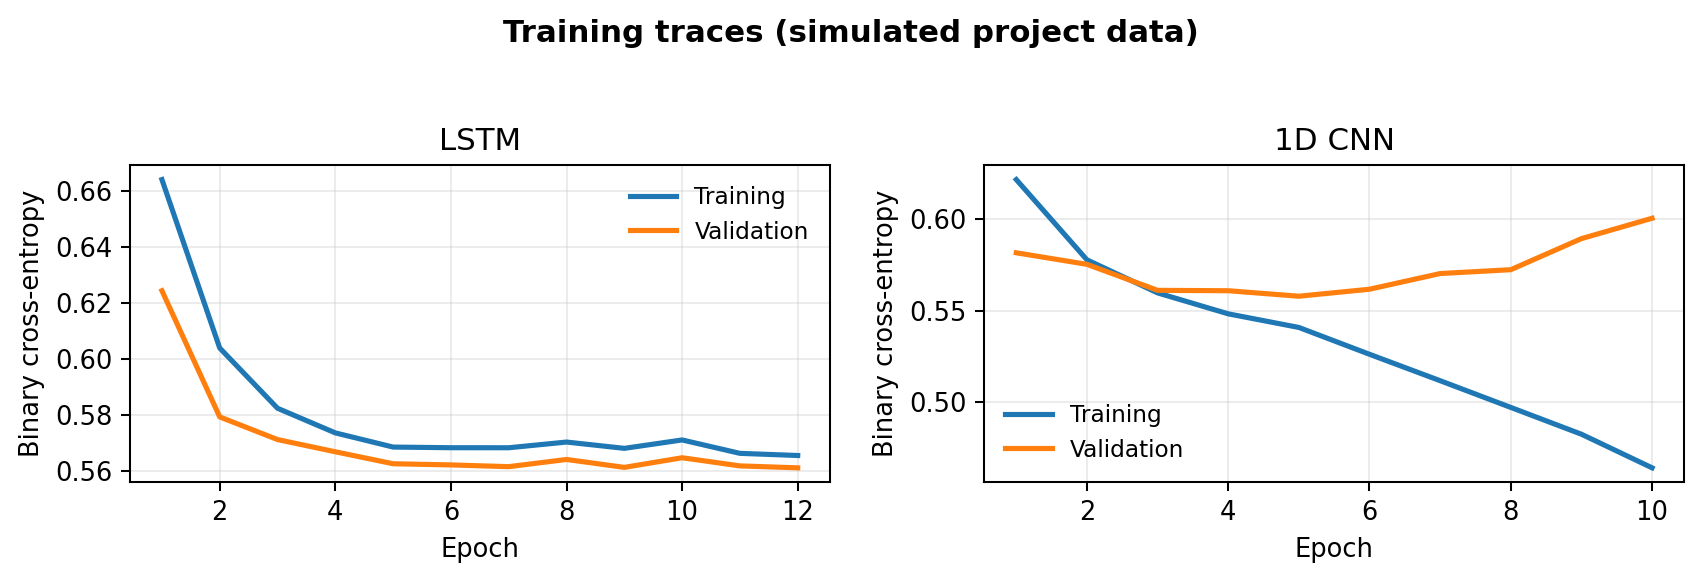

**Held-out vs shifted workflow**

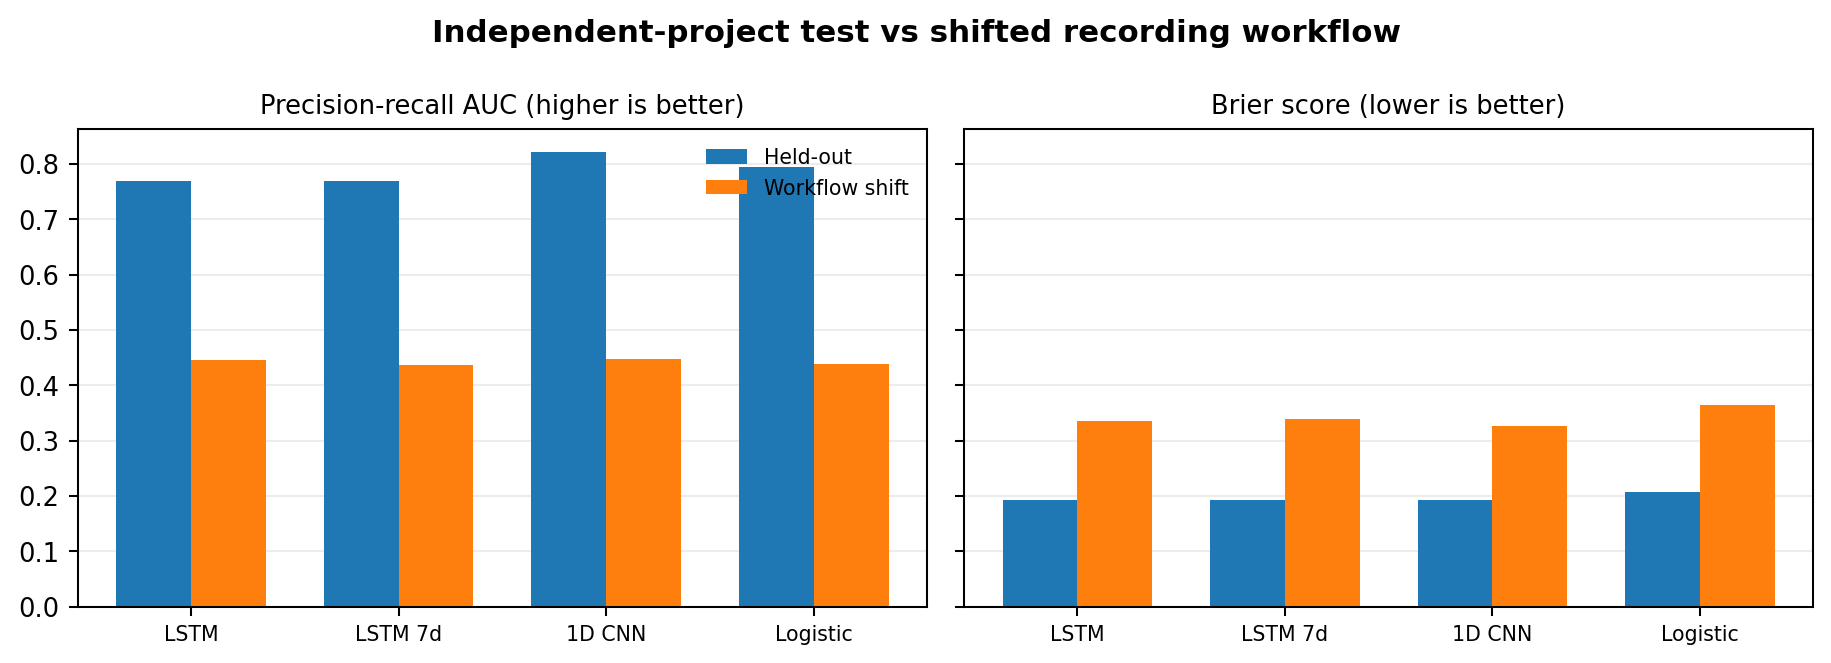

**Memory sensitivity**

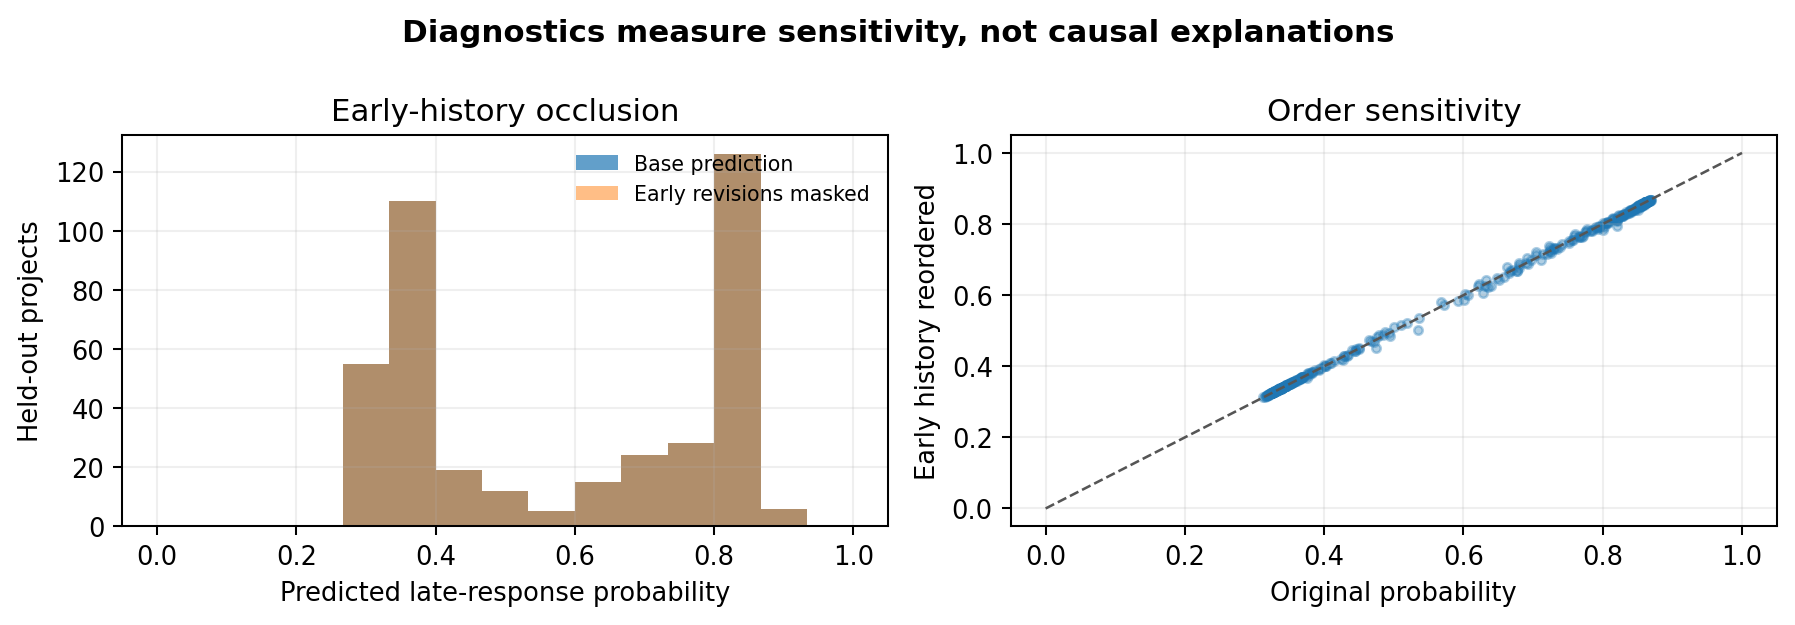

**Held-out LSTM error counts**

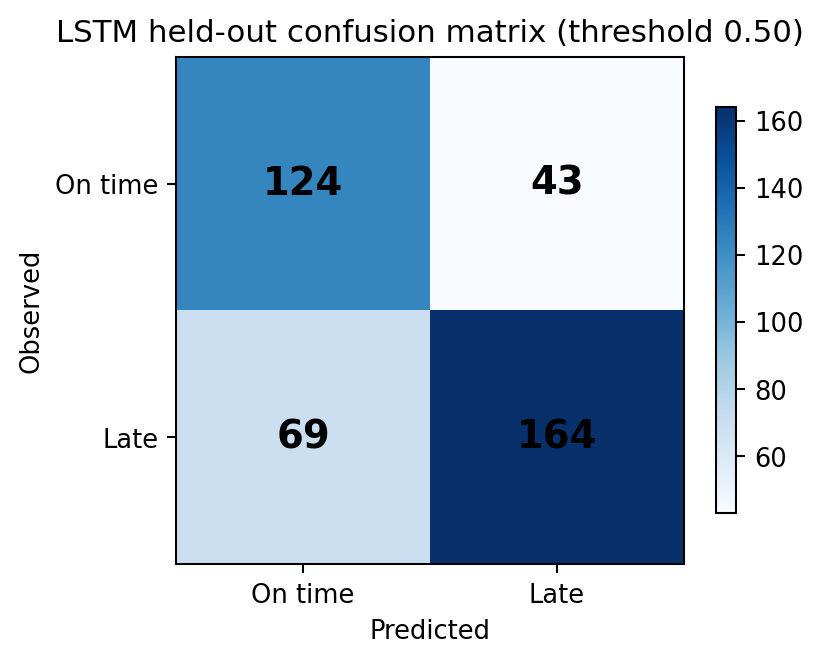

**Shifted-workflow example**

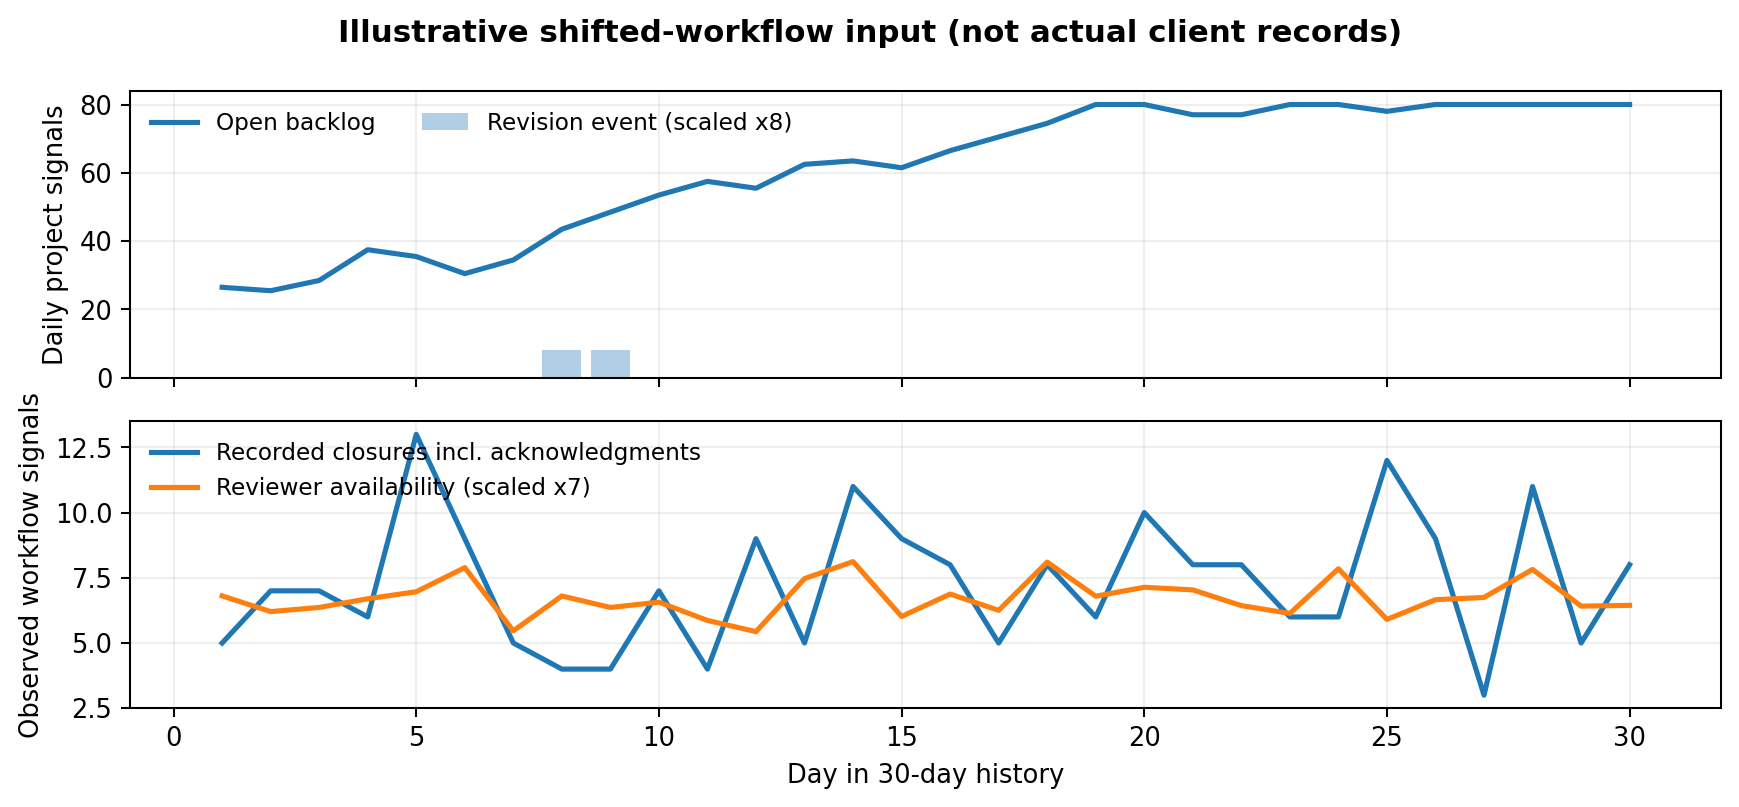

In [ ]:
from IPython.display import display, Image, Markdown
for filename, title in [
    ('learning_curves.png','Training traces'),
    ('performance.png','Held-out vs shifted workflow'),
    ('memory_diagnostics.png','Memory sensitivity'),
    ('confusion.png','Held-out LSTM error counts'),
    ('shift_sequence.png','Shifted-workflow example')]:
    display(Markdown('**'+title+'**'))
    display(Image(filename=str(OUT/filename),width=820))




### References
- Hochreiter, S., & Schmidhuber, J. (1997). Long short-term memory. *Neural Computation, 9*(8), 1735–1780. https://doi.org/10.1162/neco.1997.9.8.1735
- Géron, A. (2019). *Hands-on machine learning with Scikit-Learn, Keras, and TensorFlow* (2nd ed.). O’Reilly Media. Chapter 15.
- James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023). *An introduction to statistical learning: With applications in Python*. Springer. Chapter 10. https://doi.org/10.1007/978-3-031-38747-0
- Bai, S., Kolter, J. Z., & Koltun, V. (2018). An empirical evaluation of generic convolutional and recurrent networks for sequence modeling. *arXiv*. https://arxiv.org/abs/1803.01271
- Gama, J., Žliobaitė, I., Bifet, A., Pechenizkiy, M., & Bouchachia, A. (2014). A survey on concept drift adaptation. *ACM Computing Surveys, 46*(4), Article 44. https://doi.org/10.1145/2523813
